
# Week 1 — In-Class Hands-On: Supervised Learning Across Three Subfields

**Course:** Machine Learning in Astronomy — Week 1 In-Class Session
**Format:** Pick ONE track (A, B, or C) below based on your subfield interest, and work through it live. All three tracks practice the *same* skills from the pre-work notebook — classification, regression, evaluation metrics, cross-validation — on a *different* real, open dataset from a different subfield. At the end, everyone reconvenes to compare notes across tracks.

## Where each dataset actually comes from (read this before you start)

| Track | Subfield | Dataset | Real source |
|---|---|---|---|
| **A** | Exoplanets / Space Science | Kepler Objects of Interest (KOI), ~7,000 real Kepler transit-survey targets with expert-vetted dispositions | Originally the NASA Exoplanet Archive's KOI cumulative table, distributed as "Kepler Exoplanet Search Results" on Kaggle; loaded here from a plain-CSV mirror on GitHub (`bnarath/find_Exoplanet`) |
| **B** | Solar Physics | The classic Solar Flare dataset: 1,066 real solar active-region observations from 1978, with real subsequent 24-hour flare counts | UCI Machine Learning Repository, "Solar Flare" dataset (donated by Gary Bradshaw, 1989); loaded here from a plain-text mirror on GitHub (`calld/cs477SolarProject`) |
| **C** | Cosmology | The Pantheon Type Ia Supernova compilation: 1,048 real, spectroscopically confirmed supernovae with measured redshifts and light-curve-fit magnitudes | Scolnic et al. (2018), official data release repository (`dscolnic/Pantheon` on GitHub) — this is the actual data used in real published cosmology papers |

None of this is simulated. All three are real measurements of real astronomical objects, each with its own real messiness that you'll work through live.

## Before you start: recap & the bug story

Quick group discussion (10 min): pick 2–3 pre-work self-check questions to talk through as a class.

Then, a short case study: while building last week's pre-work notebook, a genuine bug slipped in — reusing the same variable names (`X2_train_s`, `scaler2`) for both a binary and a multi-class train/test split silently mixed up which rows belonged to which labels, and made a perfectly good classifier's ROC-AUC look like random guessing (0.49) until it was caught by noticing the AUC didn't match the model's actual accuracy. The fix: never reuse a split's variable names for a different split, and always sanity-check that your metrics agree with each other. Keep this in mind as you write your own code below.


In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    mean_squared_error, mean_absolute_error, r2_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report
)

np.random.seed(42)
%matplotlib inline
plt.rcParams['figure.dpi'] = 100
print("Environment ready. Scroll to your track: A (exoplanets), B (solar flares), or C (cosmology).")


Environment ready. Scroll to your track: A (exoplanets), B (solar flares), or C (cosmology).



---
# 🪐 Track A — Exoplanets / Space Science: Kepler Objects of Interest

**The real data:** every row is a signal detected by the Kepler space telescope that looked enough like a planet transiting its star to warrant follow-up. Experts have since labeled each one `CONFIRMED` (a real planet), `CANDIDATE` (still unresolved), or `FALSE POSITIVE` (not a real planet — often an eclipsing binary star or an instrumental artifact). Real transit parameters (orbital period, transit depth and duration, planet radius, equilibrium temperature) come from fitting a transit model to the real Kepler light curve.

### What we'll do
1. Load and inspect the real data.
2. **Classification**: predict the disposition (CONFIRMED / CANDIDATE / FALSE POSITIVE) from transit features, comparing logistic regression and k-NN side by side.
3. **Regression**: predict planet radius from transit features — and hit a real data-quality lesson along the way.
4. Cross-validate both.


In [2]:

koi_url = "https://raw.githubusercontent.com/bnarath/find_Exoplanet/main/Data/exoplanet_data.csv"
koi = pd.read_csv(koi_url)
print("Shape:", koi.shape)
print(koi['koi_disposition'].value_counts())
koi[['koi_disposition', 'koi_period', 'koi_duration', 'koi_depth', 'koi_prad', 'koi_teq', 'koi_model_snr']].head()


Shape: (6991, 41)
koi_disposition
FALSE POSITIVE    3504
CONFIRMED         1800
CANDIDATE         1687
Name: count, dtype: int64


,koi_disposition,koi_period,koi_duration,koi_depth,koi_prad,koi_teq,koi_model_snr
0,CONFIRMED,54.418383,4.50700,874.8,2.83,443,25.8
1,FALSE POSITIVE,19.899140,1.78220,10829.0,14.60,638,76.3
2,FALSE POSITIVE,1.736952,2.40641,8079.2,33.46,1395,505.6
3,CONFIRMED,2.525592,1.65450,603.3,2.75,1406,40.9
4,CONFIRMED,4.134435,3.14020,686.0,2.77,1160,40.2



### Classification: CONFIRMED vs. CANDIDATE vs. FALSE POSITIVE

We'll start deliberately simple: just two features, so we can actually *see* the decision regions in 2D. Don't expect high accuracy from only two features on a genuinely hard 3-class problem — that's the point of the second step below, not a bug in the first.


Logistic regression test accuracy (2 features): 0.5362249761677789


k-NN test accuracy (2 features):               0.5605338417540515


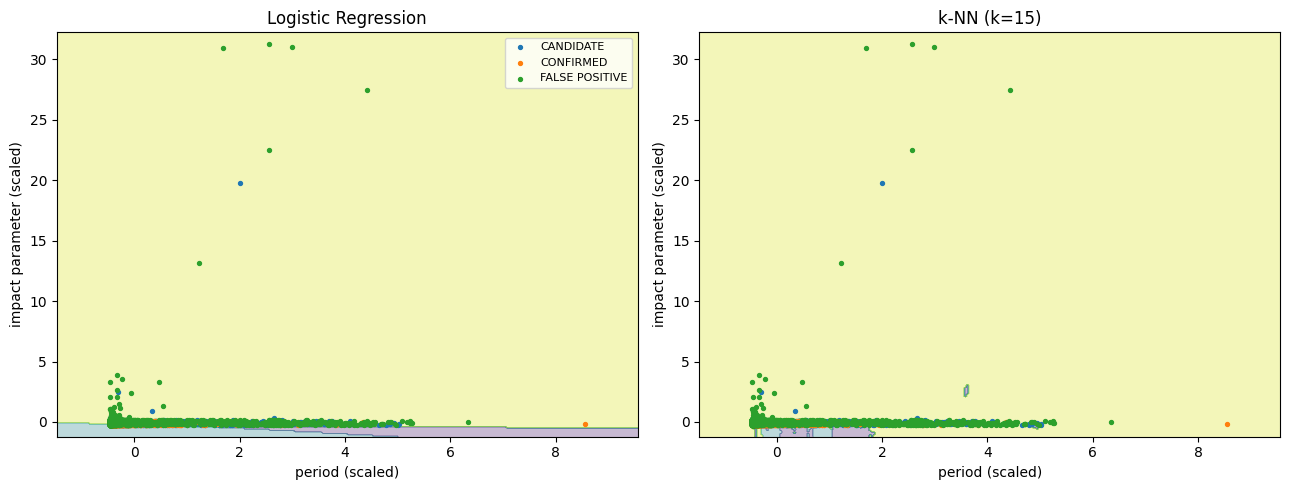

In [3]:

features_a = ['koi_period', 'koi_impact']
Xa = koi[features_a].values
ya = koi['koi_disposition'].values

Xa_train, Xa_test, ya_train, ya_test = train_test_split(Xa, ya, test_size=0.3, random_state=42, stratify=ya)

scaler_a = StandardScaler()
Xa_train_s = scaler_a.fit_transform(Xa_train)
Xa_test_s = scaler_a.transform(Xa_test)

logreg_a = LogisticRegression(max_iter=2000).fit(Xa_train_s, ya_train)
knn_a = KNeighborsClassifier(n_neighbors=15).fit(Xa_train_s, ya_train)

print("Logistic regression test accuracy (2 features):", logreg_a.score(Xa_test_s, ya_test))
print("k-NN test accuracy (2 features):              ", knn_a.score(Xa_test_s, ya_test))

# Side-by-side decision regions
classes_a = logreg_a.classes_
xx, yy = np.meshgrid(np.linspace(Xa_train_s[:, 0].min()-1, Xa_train_s[:, 0].max()+1, 300),
                      np.linspace(Xa_train_s[:, 1].min()-1, Xa_train_s[:, 1].max()+1, 300))
grid = np.c_[xx.ravel(), yy.ravel()]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, model, title in zip(axes, [logreg_a, knn_a], ['Logistic Regression', 'k-NN (k=15)']):
    Z = model.predict(grid)
    Z_num = np.array([np.where(classes_a == c)[0][0] for c in Z]).reshape(xx.shape)
    ax.contourf(xx, yy, Z_num, alpha=0.3, cmap='viridis')
    for i, c in enumerate(classes_a):
        mask = ya_train == c
        ax.scatter(Xa_train_s[mask, 0], Xa_train_s[mask, 1], s=8, label=c)
    ax.set_xlabel('period (scaled)'); ax.set_ylabel('impact parameter (scaled)')
    ax.set_title(title)
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()



**Live discussion:** the two decision-region shapes should look visibly different — logistic regression draws straight boundaries, k-NN can bend around local clusters. Neither should look impressively accurate yet, and that's expected with just two features.

### Now with more of the real features

The Kepler pipeline actually reports dozens of measured quantities per candidate. Let's use several physically meaningful ones together (still no engineered features, no vetting flags — just direct transit and stellar measurements) and see how much accuracy improves.


In [4]:

richer_features = ['koi_period', 'koi_duration', 'koi_depth', 'koi_prad', 'koi_teq',
                    'koi_model_snr', 'koi_impact', 'koi_insol', 'koi_steff', 'koi_slogg',
                    'koi_srad', 'koi_kepmag']
Xa_rich = koi[richer_features].values
Xa_rich_train, Xa_rich_test, ya_train2, ya_test2 = train_test_split(
    Xa_rich, ya, test_size=0.3, random_state=42, stratify=ya
)
scaler_rich = StandardScaler()
Xa_rich_train_s = scaler_rich.fit_transform(Xa_rich_train)
Xa_rich_test_s = scaler_rich.transform(Xa_rich_test)

logreg_rich = LogisticRegression(max_iter=2000).fit(Xa_rich_train_s, ya_train2)
print(f"Logistic regression test accuracy ({len(richer_features)} features):",
      logreg_rich.score(Xa_rich_test_s, ya_test2))


Logistic regression test accuracy (12 features): 0.6339370829361296



That should be a real, visible jump over the 2-feature version — direct evidence that feature richness matters as much as (sometimes more than) which algorithm you pick. Week 2's tree-based methods will push this further still.

### Regression: predicting planet radius — and a real data-quality trap

Check the summary statistics below before fitting anything.


In [5]:

print(koi.groupby('koi_disposition')['koi_prad'].describe()[['count', 'mean', 'std', 'min', 'max']])


                  count        mean          std   min        max
koi_disposition                                                  
CANDIDATE        1687.0   10.274132   153.042273  0.22    6140.44
CONFIRMED        1800.0    2.900372     3.176593  0.49      59.19
FALSE POSITIVE   3504.0  235.364004  4968.207806  0.14  200346.00



Notice the `FALSE POSITIVE` rows: some report a "planet radius" in the tens of thousands of Earth radii — larger than entire star systems, physically impossible for an actual planet. This happens because false positives (often eclipsing binary stars) get fit with a planet-transit model that doesn't actually describe what's happening, so the fitted "radius" comes out meaningless. **This is a live example of exactly the lesson from pre-work Section 5**: mixing physically incoherent populations into one regression wrecks it. We'll fit only on `CONFIRMED` planets, where the radius values are physically sane.


RMSE: 2.711 Earth radii
MAE:  0.946 Earth radii
R^2:  0.421


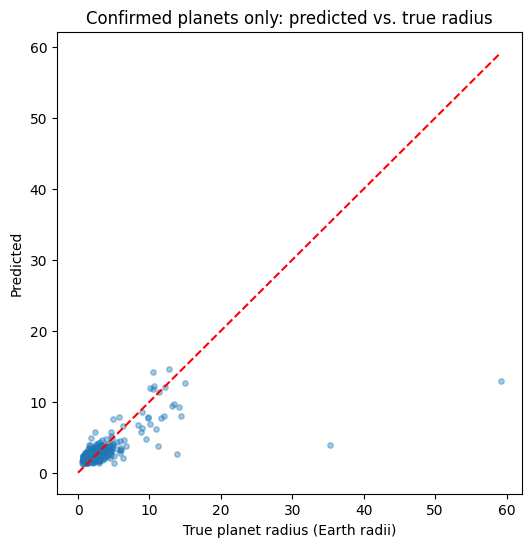

In [6]:

confirmed = koi[koi['koi_disposition'] == 'CONFIRMED']
reg_features = ['koi_period', 'koi_duration', 'koi_depth', 'koi_teq', 'koi_model_snr']
Xr = confirmed[reg_features].values
yr = confirmed['koi_prad'].values

Xr_train, Xr_test, yr_train, yr_test = train_test_split(Xr, yr, test_size=0.3, random_state=42)
scaler_r = StandardScaler()
Xr_train_s = scaler_r.fit_transform(Xr_train)
Xr_test_s = scaler_r.transform(Xr_test)

reg_a = LinearRegression().fit(Xr_train_s, yr_train)
yr_pred = reg_a.predict(Xr_test_s)

print(f"RMSE: {np.sqrt(mean_squared_error(yr_test, yr_pred)):.3f} Earth radii")
print(f"MAE:  {mean_absolute_error(yr_test, yr_pred):.3f} Earth radii")
print(f"R^2:  {r2_score(yr_test, yr_pred):.3f}")

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(yr_test, yr_pred, alpha=0.4, s=15)
lims = [0, max(yr_test.max(), yr_pred.max())]
ax.plot(lims, lims, 'r--')
ax.set_xlabel('True planet radius (Earth radii)'); ax.set_ylabel('Predicted')
ax.set_title('Confirmed planets only: predicted vs. true radius')
plt.show()


In [7]:

# Cross-validate both models
cv_class_a = cross_val_score(LogisticRegression(max_iter=2000), scaler_a.fit_transform(Xa), ya, cv=5)
cv_reg_a = cross_val_score(LinearRegression(), scaler_r.fit_transform(Xr), yr, cv=5, scoring='r2')
print("Classification accuracy across folds:", np.round(cv_class_a, 3), " mean:", cv_class_a.mean().round(3))
print("Regression R^2 across folds:        ", np.round(cv_reg_a, 3), " mean:", cv_reg_a.mean().round(3))


Classification accuracy across folds: [0.538 0.499 0.466 0.53  0.485]  mean: 0.503
Regression R^2 across folds:         [ 0.426  0.721 -0.26   0.669  0.293]  mean: 0.37



**🔧 Try it yourself / group challenge:**
- Refit the regression *without* filtering to `CONFIRMED` only, and watch R² collapse — direct, real confirmation of why the filtering mattered.
- Add the four `koi_fpflag_*` vetting flags into the richer feature set and see how much further accuracy climbs — these are the pipeline's own automated false-positive tests, and they're strong predictors precisely because they were designed to be.
- Reframe the regression target as classification: bin `koi_prad` into "Earth-like" (<1.5), "super-Earth/mini-Neptune" (1.5–6), "giant" (>6), and train a classifier instead. Which framing feels more useful for someone hunting for potentially habitable planets?



---
# ☀️ Track B — Solar Physics: Predicting Solar Flares

**The real data:** each row is one real solar active region observed in 1978, described by its magnetic complexity class (the "modified Zurich class"), spot size and distribution codes, and recent activity — followed by how many C-class, M-class, and X-class flares that region actually produced in the next 24 hours. This is real historical solar-monitoring data, not a simulation.

### What we'll do
1. Load and parse the real (slightly unusually-formatted) data.
2. **Classification**: will this region produce at least one flare in the next 24 hours?
3. **Regression**: predict how many flares.
4. Cross-validate both, and confront real class imbalance.


In [8]:

flare_url = "https://raw.githubusercontent.com/calld/cs477SolarProject/master/flaredata2.txt"
col_names = ['zurich_class', 'spot_size', 'spot_distribution', 'activity', 'evolution',
             'prev_24hr_activity', 'hist_complex', 'became_complex', 'area', 'area_largest_spot',
             'c_class_count', 'm_class_count', 'x_class_count']

# The first line is a plain-text header comment, not data - skip it.
flares = pd.read_csv(flare_url, sep=r'\s+', skiprows=1, names=col_names)
print("Shape:", flares.shape)
flares.head()


Shape: (1066, 13)


,zurich_class,spot_size,spot_distribution,activity,evolution,prev_24hr_activity,hist_complex,became_complex,area,area_largest_spot,c_class_count,m_class_count,x_class_count
0,H,A,X,1,3,1,1,1,1,1,0,0,0
1,D,R,O,1,3,1,1,2,1,1,0,0,0
2,C,S,O,1,3,1,1,2,1,1,0,0,0
3,H,R,X,1,2,1,1,1,1,1,0,0,0
4,H,S,X,1,1,1,1,2,1,1,0,0,0



### Feature encoding
`zurich_class`, `spot_size`, and `spot_distribution` are categorical (letter codes), so — exactly as flagged in pre-work Section 4 — we need to one-hot encode them before any numeric model can use them.


In [9]:

flares_encoded = pd.get_dummies(flares, columns=['zurich_class', 'spot_size', 'spot_distribution'])
flares_encoded['will_flare'] = ((flares['c_class_count'] + flares['m_class_count'] + flares['x_class_count']) > 0).astype(int)
flares_encoded['total_flares'] = flares['c_class_count'] + flares['m_class_count'] + flares['x_class_count']

print("Fraction of regions that flared at all:", flares_encoded['will_flare'].mean().round(3))
flares_encoded.filter(regex='zurich_class_|spot_size_|will_flare|total_flares').head()


Fraction of regions that flared at all: 0.189


,zurich_class_B,zurich_class_C,zurich_class_D,zurich_class_E,zurich_class_F,zurich_class_H,spot_size_A,spot_size_H,spot_size_K,spot_size_R,spot_size_S,spot_size_X,will_flare,total_flares
0,False,False,False,False,False,True,True,False,False,False,False,False,0,0
1,False,False,True,False,False,False,False,False,False,True,False,False,0,0
2,False,True,False,False,False,False,False,False,False,False,True,False,0,0
3,False,False,False,False,False,True,False,False,False,True,False,False,0,0
4,False,False,False,False,False,True,False,False,False,False,True,False,0,0



Notice the class balance printed above — most active regions did **not** produce a flare in the next 24 hours. This is real, naturally-occurring imbalance (flares are relatively rare events), exactly the situation pre-work Section 7 warned makes plain accuracy misleading.


Accuracy: 0.796875

Classification report:
               precision    recall  f1-score   support

           0       0.84      0.92      0.88       260
           1       0.43      0.27      0.33        60

    accuracy                           0.80       320
   macro avg       0.64      0.59      0.61       320
weighted avg       0.77      0.80      0.78       320



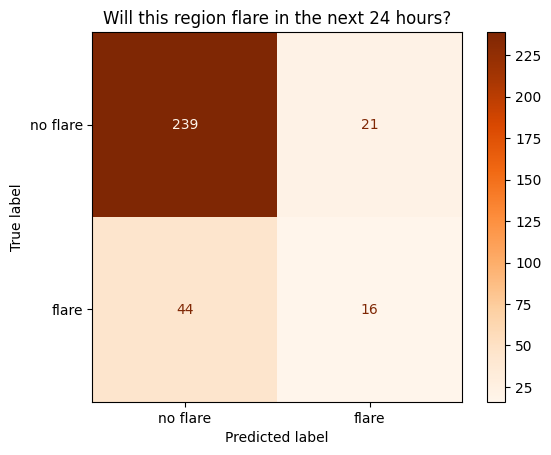

In [10]:

feature_cols = [c for c in flares_encoded.columns if c not in
                ['c_class_count', 'm_class_count', 'x_class_count', 'will_flare', 'total_flares']]
Xb = flares_encoded[feature_cols].values
yb_class = flares_encoded['will_flare'].values

Xb_train, Xb_test, yb_train, yb_test = train_test_split(Xb, yb_class, test_size=0.3, random_state=42, stratify=yb_class)
scaler_b = StandardScaler()
Xb_train_s = scaler_b.fit_transform(Xb_train)
Xb_test_s = scaler_b.transform(Xb_test)

logreg_b = LogisticRegression(max_iter=2000).fit(Xb_train_s, yb_train)
yb_pred = logreg_b.predict(Xb_test_s)

print("Accuracy:", logreg_b.score(Xb_test_s, yb_test))
print("\nClassification report:\n", classification_report(yb_test, yb_pred))

cm_b = confusion_matrix(yb_test, yb_pred)
ConfusionMatrixDisplay(cm_b, display_labels=['no flare', 'flare']).plot(cmap='Oranges')
plt.title('Will this region flare in the next 24 hours?')
plt.show()



**Live discussion:** compare the overall accuracy to the recall for the "flare" class specifically. If there's a gap, that's the imbalance problem showing up in real data, not a hypothetical.

### Regression: how many flares?


In [11]:

yb_reg = flares_encoded['total_flares'].values
Xr_train, Xr_test, yr_train, yr_test = train_test_split(Xb, yb_reg, test_size=0.3, random_state=42)
scaler_br = StandardScaler()
Xr_train_s = scaler_br.fit_transform(Xr_train)
Xr_test_s = scaler_br.transform(Xr_test)

reg_b = LinearRegression().fit(Xr_train_s, yr_train)
yr_pred = reg_b.predict(Xr_test_s)

print(f"MAE: {mean_absolute_error(yr_test, yr_pred):.3f} flares")
print(f"R^2: {r2_score(yr_test, yr_pred):.3f}")
print("\nNote: flare counts are non-negative integers with a lot of zeros (most regions flare zero times) -")
print("a 'count' target like this is better modeled with Poisson regression than plain linear regression,")
print("(recall the Poisson distribution from Notebook 0 Section 5) - linear regression here is a simple")
print("first attempt, not the statistically ideal choice.")


MAE: 0.478 flares
R^2: 0.051

Note: flare counts are non-negative integers with a lot of zeros (most regions flare zero times) -
a 'count' target like this is better modeled with Poisson regression than plain linear regression,
(recall the Poisson distribution from Notebook 0 Section 5) - linear regression here is a simple
first attempt, not the statistically ideal choice.


In [12]:

cv_class_b = cross_val_score(LogisticRegression(max_iter=2000), scaler_b.fit_transform(Xb), yb_class, cv=5)
cv_reg_b = cross_val_score(LinearRegression(), scaler_br.fit_transform(Xb), yb_reg, cv=5, scoring='r2')
print("Classification accuracy across folds:", np.round(cv_class_b, 3), " mean:", cv_class_b.mean().round(3))
print("Regression R^2 across folds:        ", np.round(cv_reg_b, 3), " mean:", cv_reg_b.mean().round(3))


Classification accuracy across folds: [0.799 0.826 0.831 0.817 0.798]  mean: 0.814
Regression R^2 across folds:         [0.139 0.155 0.121 0.235 0.111]  mean: 0.152



**🔧 Try it yourself / group challenge:**
- Try predicting only whether an X-class (severe) flare occurs, instead of any flare — watch the imbalance get much more extreme, and see how that affects precision/recall for the rare class.
- Drop the one-hot encoded `zurich_class` columns entirely and refit — how much does classification accuracy depend on that one feature versus the numeric features?
- This dataset is from 1978. Discuss: what would you want to check before trusting a model trained on this data to say anything about the Sun's behavior today?



---
# 🌌 Track C — Cosmology: The Pantheon Type Ia Supernova Hubble Diagram

**The real data:** each row is one real, spectroscopically confirmed Type Ia supernova — the "standard candles" used to discover the accelerating expansion of the universe. Each has a real measured redshift and a real SALT2 light-curve-fit magnitude (`mb`, already corrected for stretch and color using the same kind of Tripp-formula correction described in the original papers). This is the actual published Pantheon compilation.

### What we'll do
1. Load the real data and reproduce the classic Hubble diagram.
2. **Regression**: fit magnitude vs. log-redshift — literally the Hubble law, live.
3. **Classification**: a direct, hands-on rerun of pre-work Section 3's "regression or classification?" question — bin supernovae into low-z/high-z and classify instead of regress.
4. Cross-validate.


In [13]:

pantheon_url = "https://raw.githubusercontent.com/dscolnic/Pantheon/master/lcparam_full_long.txt"
sne = pd.read_csv(pantheon_url, sep=r'\s+', engine='python')
sne = sne.rename(columns={'#name': 'name'})
print("Shape:", sne.shape)
sne[['name', 'zcmb', 'mb', 'dmb']].head()


Shape: (1048, 19)


,name,zcmb,mb,dmb
0,03D1au,0.50309,22.93445,0.12605
1,03D1ax,0.49480,22.88020,0.11765
2,03D1co,0.67767,24.03770,0.20560
3,03D1ew,0.86650,24.34685,0.17385
4,03D1fq,0.79857,24.36050,0.17435


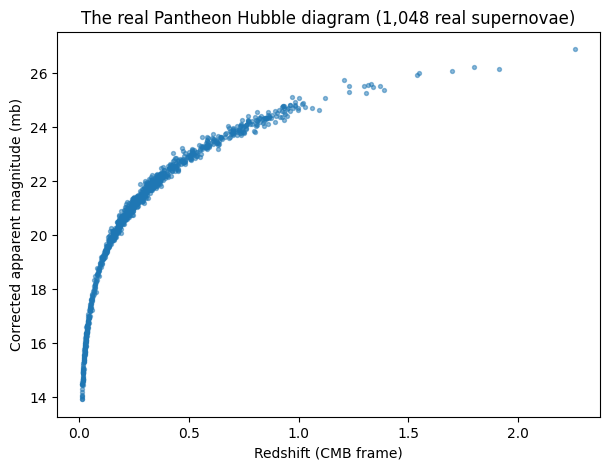

In [14]:

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(sne['zcmb'], sne['mb'], s=8, alpha=0.5)
ax.set_xlabel('Redshift (CMB frame)'); ax.set_ylabel('Corrected apparent magnitude (mb)')
ax.set_title('The real Pantheon Hubble diagram (1,048 real supernovae)')
plt.show()



### Regression: recovering the Hubble law

At the redshifts and precision relevant here, magnitude scales roughly linearly with $\log_{10}(z)$ — this is the standard way a Hubble diagram is actually plotted and fit in the literature.


RMSE: 0.171 mag
R^2:  0.996


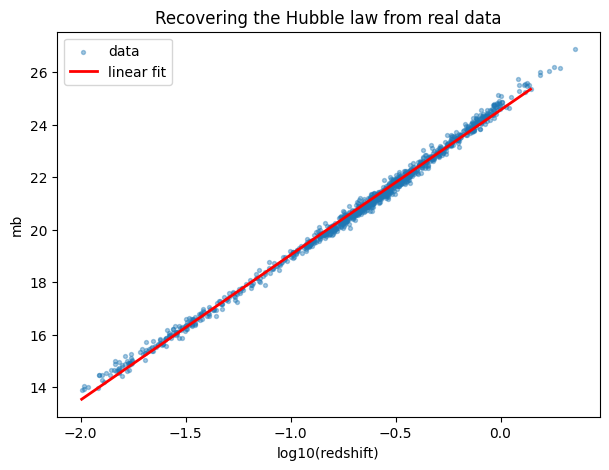

In [ ]:
sne['log_z'] = np.log10(sne['zcmb'])
Xc = sne[['log_z']].values
yc = sne['mb'].values

Xc_train, Xc_test, yc_train, yc_test = train_test_split(Xc, yc, test_size=0.3, random_state=42)
reg_c = LinearRegression().fit(Xc_train, yc_train)
yc_pred = reg_c.predict(Xc_test)

print(f"RMSE: {np.sqrt(mean_squared_error(yc_test, yc_pred)):.3f} mag")
print(f"R^2:  {r2_score(yc_test, yc_pred):.3f}")

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(sne['log_z'], sne['mb'], s=8, alpha=0.4, label='data')
order = np.argsort(Xc_test[:, 0])
ax.plot(Xc_test[order], yc_pred[order], 'r-', lw=2, label='linear fit')
ax.set_xlabel('log10(redshift)'); ax.set_ylabel('mb')
ax.set_title('Recovering the Hubble law from real data')
ax.legend()
plt.show()



That R² should be very high — this is one of the tightest, most famous relations in observational cosmology, and you just fit it yourself on real published data.

### Classification: the pre-work "regression or classification?" example, live

Pre-work Section 3 raised photometric redshift binning as a case where the *same* problem could be framed as regression or classification. Here's a live version: instead of predicting the continuous redshift, we'll classify each supernova as "low-z" ($z < 0.1$) or "high-z" ($z \geq 0.1$), using the light-curve-fit magnitude and its uncertainty as features.


Accuracy: 0.9873015873015873


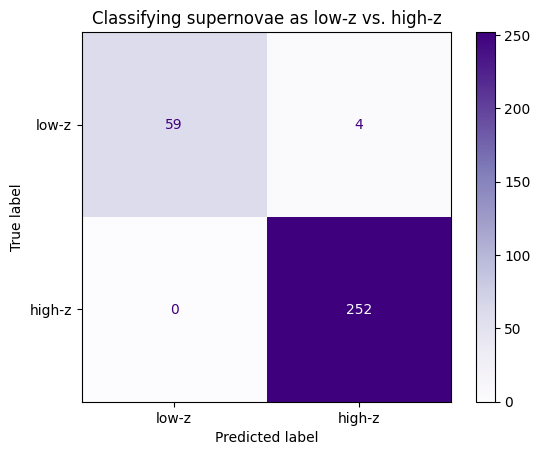

In [16]:

sne['z_bin'] = (sne['zcmb'] >= 0.1).astype(int)  # 0 = low-z, 1 = high-z
Xcc = sne[['mb', 'dmb']].values
ycc = sne['z_bin'].values

Xcc_train, Xcc_test, ycc_train, ycc_test = train_test_split(Xcc, ycc, test_size=0.3, random_state=42, stratify=ycc)
scaler_c = StandardScaler()
Xcc_train_s = scaler_c.fit_transform(Xcc_train)
Xcc_test_s = scaler_c.transform(Xcc_test)

logreg_c = LogisticRegression().fit(Xcc_train_s, ycc_train)
ycc_pred = logreg_c.predict(Xcc_test_s)

print("Accuracy:", logreg_c.score(Xcc_test_s, ycc_test))
cm_c = confusion_matrix(ycc_test, ycc_pred)
ConfusionMatrixDisplay(cm_c, display_labels=['low-z', 'high-z']).plot(cmap='Purples')
plt.title('Classifying supernovae as low-z vs. high-z')
plt.show()



**Live discussion — this is the important part:** that accuracy is probably very high. Why? Because `mb` (apparent magnitude) is itself almost a direct stand-in for distance, and distance is what determines redshift in the first place — the classifier isn't learning anything the regression above didn't already know, it's just seeing the same information through a coarser lens. This is exactly the caution from pre-work Section 3: reframing a regression problem as classification doesn't create new information, and sometimes just throws information away. Contrast this with the Week 1 pre-work redshift-binning example, where the same caution applied for the same reason.


In [17]:

cv_reg_c = cross_val_score(LinearRegression(), Xc, yc, cv=5, scoring='r2')
cv_class_c = cross_val_score(LogisticRegression(), scaler_c.fit_transform(Xcc), ycc, cv=5)
print("Regression R^2 across folds:      ", np.round(cv_reg_c, 3), " mean:", cv_reg_c.mean().round(3))
print("Classification accuracy across folds:", np.round(cv_class_c, 3), " mean:", cv_class_c.mean().round(3))


Regression R^2 across folds:       [0.946 0.984 0.994 0.994 0.99 ]  mean: 0.982
Classification accuracy across folds: [0.938 1.    1.    1.    0.976]  mean: 0.983



**🔧 Try it yourself / group challenge:**
- Move the low-z/high-z boundary from `z = 0.1` to `z = 0.3` and refit — does accuracy change much? What does that tell you about where these supernovae are concentrated in redshift (look back at your Hubble diagram)?
- Try fitting the regression with plain `zcmb` instead of `log_z` — does R² change much, and does the residual pattern look different?
- The original Pantheon paper fits a full cosmological model (not just a straight line) to this exact relationship to measure $\Omega_m$ and dark energy parameters. Discuss: what would a straight-line fit like ours miss that a full cosmological model wouldn't?



---
# Cross-Track Share-Out & Wrap-Up

## Share-out (each track reports back)
For your track, report to the room:
1. One number: your best classification accuracy or regression R².
2. One surprise: something in the real data that didn't behave the way you expected.

## Connect to your own data
Regardless of which track you worked on: think about your own thesis data.
- Is your natural next question a regression or a classification problem — and could it reasonably be framed either way, the way Track C's redshift binning could?
- What real messiness (missing values, sentinel codes, physically implausible outliers, class imbalance) would you need to check for before modeling it, the way Track A had to filter false-positive planet radii and Track B had to confront flare-class imbalance?

## Bridge to Week 2
Every model this week assumed you already had correct labels to learn from. Next week: what do you do when you don't have any labels at all — or only a handful? That's unsupervised and semi-supervised learning.
